# Fitting TemGym's projection lenses to the NEOARM recording of 10 November 2026

The stage-1 recording (`at_the_microscope/record_projection_response.py`, then called `stage1_record.py`, 200 kV) measured how far a beam shift (CLA1, in MAG 40k) or a beam tilt
(CLA2, in DIFF 40 cm) displaces the beam on the camera, at 20 settings of IL1, IL2, IL3 and PL1. Here a TemGym column is
fitted to those displacements, so that it predicts the displacement for other DAC values.

Everything optical goes through TemGym: each lens is a `temgym_core.components.ElectromagneticLens`, and A and B
(the displacement on the camera per metre of shift and per radian of tilt at the specimen) come from
`temgym_core.run.position_and_angle_response`. JAX differentiates through TemGym for the fit.

This is a fit, not an inversion: it reproduces the displacements, but the lens positions it uses are not the real ones
(section 6 shows equally good fits with very different positions).

In [1]:
import csv, io, json, os, zipfile
from pathlib import Path

os.environ["JAX_PLATFORMS"] = "cpu"
import jax
import jax.numpy as jnp
import numpy as np
from jax.flatten_util import ravel_pytree
from scipy.optimize import least_squares

jax.config.update("jax_enable_x64", True)
from temgym_core.components import ElectromagneticLens, Plane
from temgym_core.constants import compute_Rc_from_voltage
from temgym_core.run import position_and_angle_response

RECORDINGS = Path("recordings/2026-11-10")      # the two recordings of that day, as copied from the microscope PC
RESULTS = Path("results")                        # what this notebook saves
LENSES = ["IL1", "IL2", "IL3", "PL1"]
VOLTAGE = 200e3
PIXEL = 110e-6                      # camera pixel (m); its value only scales the deflector sizes

## 1. The recording: one row per frame

In [2]:
archive = zipfile.ZipFile(RECORDINGS / "imaging-system-fitting-40k-40cm.zip")
table_name = next(name for name in archive.namelist() if name.endswith("table.csv"))
table = list(csv.DictReader(io.TextIOWrapper(archive.open(table_name))))
print(table_name)
print(len(table), "frames;", sum(row["beam_usable"] != "True" for row in table), "where the beam was not usable")


def centre(row):
    return complex(float(row["beam_x_px"]), float(row["beam_y_px"]))


def lens_values(row):
    return [float(row[name]) for name in LENSES]

output/stage1_neoarm/projection_response_2026-11-10_154655/table.csv
196 frames; 0 where the beam was not usable


## 2. The displacements

**Fitted:** at each of the 20 settings the deflector went + and - along x and along y. The displacement is half the
difference of the two beam centres, so where the beam started cancels.

**Kept back for testing:** while the script was choosing its lens steps it also took, at 32 other lens settings,
one frame not deflected and one deflected along x. Those are not fitted.

In [3]:
plus, minus = {}, {}
for row in table:
    if row["number"]:
        key = (row["mode"], row["number"], row["direction"])
        if row["role"] == "deflected +":
            plus[key] = row
        if row["role"] == "deflected -":
            minus[key] = row
fitted = [dict(mode=p["mode"], setting=p["setting"], deflector=p["deflector"], direction=p["direction"],
               lenses=lens_values(p), deflection=complex(float(p["deflection_x"]), float(p["deflection_y"])),
               displacement=(centre(p) - centre(minus[key])) / 2) for key, p in plus.items()]

kept_back, before = [], None
for row in table:
    if not row["number"]:
        if row["role"] == "not deflected":
            before = row
        elif row["role"] == "deflected":
            kept_back.append(dict(mode=row["mode"], setting=row["setting"], deflector=row["deflector"],
                                  lenses=lens_values(row), deflection=complex(float(row["deflection_x"]), 0.0),
                                  displacement=centre(row) - centre(before)))
print(len(fitted), "fitted displacements;", len(kept_back), "one-sided displacements kept back")


def as_arrays(displacements):
    return dict(lenses=np.array([m["lenses"] for m in displacements]), is_tilt=np.array([m["deflector"] == "CLA2" for m in displacements]),
                deflection=np.array([m["deflection"] for m in displacements]), displacement=np.array([m["displacement"] for m in displacements]))


data = as_arrays(fitted)

40 fitted displacements; 47 one-sided displacements kept back


## 3. How well a displacement repeats

The console's own lens values were recorded twice in each mode (first and last). The difference is the scatter the
fit is judged against. It includes whatever the lens changes in between left behind.

In [4]:
scatter = {}
for mode in ["MAG 40k", "DIFF 40 cm"]:
    differences = []
    for direction in "xy":
        repeats = np.array([m["displacement"] for m in fitted if m["setting"] == f"{mode} row" and m["direction"] == direction])
        differences.extend(repeats - repeats.mean())
    scatter[mode] = float(np.sqrt(np.sum(np.abs(differences) ** 2) / 2 / (len(differences) - 2)))
    size = np.mean([abs(m["displacement"]) for m in fitted if m["mode"] == mode])
    print(f"{mode}: a displacement of about {size:.0f} px repeats to {scatter[mode]:.3f} px")
data["scatter"] = np.array([scatter[m["mode"]] for m in fitted])

MAG 40k: a displacement of about 119 px repeats to 0.041 px
DIFF 40 cm: a displacement of about 95 px repeats to 0.126 px


## 4. Each lens turns the image in proportion to its DAC value

A magnetic lens turns the image by an angle proportional to its ampere-turns, whatever the shape of its field. So
the turn of the displacement per DAC unit, read straight from the data, gives each lens's ampere-turns per DAC unit
(TemGym's `compute_Rc_from_voltage` is the turn per ampere-turn at 200 kV).

In [5]:
turn_per_ampere_turn = float(compute_Rc_from_voltage(VOLTAGE))
row_40k = next(m for m in fitted if m["setting"] == "MAG 40k row" and m["direction"] == "x")
ampere_turns_per_unit = []
for i, name in enumerate(LENSES):
    steps, turns = [], []
    for m in fitted:
        change = np.array(m["lenses"]) - np.array(row_40k["lenses"])
        if m["mode"] == "MAG 40k" and m["direction"] == "x" and np.count_nonzero(change) <= 1 and (change[i] or not change.any()):
            steps.append(change[i])
            turns.append(np.angle(m["displacement"] / row_40k["displacement"]))
    rate = np.polyfit(steps, turns, 1)[0]                       # rad per DAC unit, as seen on the camera
    ampere_turns_per_unit.append(rate / turn_per_ampere_turn)
    print(f"{name}: the image turns {np.degrees(rate) * 1000:+.3f} degrees per 1000 DAC units = "
          f"{abs(ampere_turns_per_unit[-1]):.4f} ampere-turns per unit ({abs(ampere_turns_per_unit[-1]) * 65535:.0f} at full range)")
ampere_turns_per_unit = np.array(ampere_turns_per_unit)

IL1: the image turns -1.741 degrees per 1000 DAC units = 0.0798 ampere-turns per unit (5227 at full range)
IL2: the image turns -1.752 degrees per 1000 DAC units = 0.0803 ampere-turns per unit (5260 at full range)
IL3: the image turns -1.777 degrees per 1000 DAC units = 0.0814 ampere-turns per unit (5334 at full range)
PL1: the image turns +1.764 degrees per 1000 DAC units = 0.0808 ampere-turns per unit (5295 at full range)


## 5. The TemGym column

Specimen, objective, IL1, IL2, IL3, PL1, camera. Every lens is a TemGym `ElectromagneticLens`, with its own free
numbers:

* **ampere-turns per DAC unit** (sets the image rotation, and the excitation),
* **Gc** (strength: focal length = V* / (Gc x ampere-turns squared)),
* **Tc** (thickness: the lens is two half-strength lenses, Tc x ampere-turns apart),
* the **gap** to the lens before it.

The objective never changes in this recording, so it has one number for its strength and none for thickness.
No field shape is assumed.

In [6]:
def column(numbers, dac):
    """TemGym components from the specimen to the camera, for IL1, IL2, IL3, PL1 at these DAC values."""
    gaps = jnp.exp(numbers["log_gaps"])                 # specimen-objective, objective-IL1, IL1-IL2, IL2-IL3, IL3-PL1, PL1-camera
    z = jnp.cumsum(gaps)
    objective = ElectromagneticLens(z=z[0], turns=1.0, current=1.0, Gc=jnp.exp(numbers["log_objective_Gc"]))
    lenses = [ElectromagneticLens(z=z[i + 1], turns=numbers["ampere_turns_per_unit"][i], current=dac[i],
                                  Gc=jnp.exp(numbers["log_Gc"][i]), Tc=jnp.exp(numbers["log_Tc"][i])) for i in range(4)]
    return [objective, *lenses, Plane(z=z[5])]


a_and_b = jax.jit(jax.vmap(lambda numbers, dac: position_and_angle_response(column(numbers, dac), voltage=VOLTAGE),
                           in_axes=(None, 0)))

A deflection along a deflector's x and y becomes a shift (CLA1) or a tilt (CLA2) at the specimen; each deflector has
its own axes. A turns the shift, and B the tilt, into a displacement on the camera, which the camera turns by its rotation.

In [7]:
def at_specimen(axes, deflection):
    x_axis = jnp.exp(axes["log_size"] + 1j * axes.get("x_angle", 0.0))
    return x_axis * (deflection.real + (axes["y_axis"][0] + 1j * axes["y_axis"][1]) * deflection.imag)


def predicted_displacements(numbers, data):
    """How far each deflection displaces the beam on the camera (px, x + iy)."""
    a, b = a_and_b(numbers["lenses"], data["lenses"])
    on_camera = jnp.where(data["is_tilt"], b * at_specimen(numbers["CLA2"], data["deflection"]),
                          a * at_specimen(numbers["CLA1"], data["deflection"]))
    return jnp.exp(1j * numbers["camera_rotation"]) * on_camera / PIXEL

## 6. The fit

Two scales cannot come from this recording and are held: the PL1-to-camera gap (0.34 m) and the shift per CLA1 unit
(1e-11 m). A grating image and a gold-ring pattern would replace them.

The ampere-turns start from section 4. The gaps, strengths and thicknesses start from many random guesses, because a
single start can end in a poor fit. The misfit is counted in units of the repeat scatter.

In [8]:
HELD_GAP, HELD_CLA1_SIZE = np.log(0.34), np.log(1e-11)


def with_held(free):
    lenses = dict(free["lenses"], log_gaps=jnp.r_[free["lenses"]["log_gaps"], HELD_GAP])
    return dict(free, lenses=lenses, CLA1=dict(free["CLA1"], log_size=HELD_CLA1_SIZE))


def misfits(values, as_numbers):
    """Predicted minus measured displacement, in units of the repeat scatter (real parts, then imaginary parts)."""
    misfit = (predicted_displacements(with_held(as_numbers(values)), data) - data["displacement"]) / data["scatter"]
    return jnp.concatenate([misfit.real, misfit.imag])


def fit(start):
    start_list, as_numbers = ravel_pytree(start)
    if "compiled" not in fit.__dict__:                   # compile once; every start has the same layout
        fit.compiled = (jax.jit(lambda values: misfits(values, as_numbers)),
                        jax.jit(jax.jacfwd(lambda values: misfits(values, as_numbers))))
    result = least_squares(fit.compiled[0], np.asarray(start_list), jac=fit.compiled[1], method="lm",
                           xtol=1e-12, ftol=1e-12, gtol=1e-12, max_nfev=200)
    return dict(numbers=with_held(as_numbers(result.x)), chi2=float(result.fun @ result.fun),
                dof=len(result.fun) - len(result.x))


def random_start(rng):
    ampere_turns_40k = np.abs(ampere_turns_per_unit) * np.array(row_40k["lenses"])
    v_star = 239e3
    lenses = dict(ampere_turns_per_unit=ampere_turns_per_unit,
                  log_gaps=np.log([0.001, 0.1, 0.1, 0.1, 0.15]) + rng.normal(0, 0.8, 5),
                  log_objective_Gc=np.log(v_star / 0.001) + rng.normal(0, 1.0),
                  log_Gc=np.log(v_star / (0.02 * ampere_turns_40k ** 2)) + rng.normal(0, 1.0, 4),
                  log_Tc=np.log(0.003 / ampere_turns_40k) + rng.normal(0, 1.0, 4))
    start = dict(lenses=lenses, camera_rotation=0.0, CLA1=dict(y_axis=np.array([0.0, 1.0])),
                 CLA2=dict(log_size=0.0, x_angle=0.0, y_axis=np.array([0.0, 1.0])))
    # size the tilt, and the shift (through the first gap), and turn the camera, so the start is in the right region
    shift, tilt = ~data["is_tilt"], data["is_tilt"]
    seen = np.asarray(predicted_displacements(with_held(start), data))
    start["CLA2"]["log_size"] = float(np.log(np.median(np.abs(data["displacement"][tilt]) / np.abs(seen[tilt]))))
    rotation = np.angle(np.vdot(seen[shift], data["displacement"][shift]))
    start["camera_rotation"] = float(rotation)
    start["CLA2"]["x_angle"] = float(np.angle(np.vdot(seen[tilt], data["displacement"][tilt])) - rotation)
    return start

In [9]:
STARTS = 40
rng = np.random.default_rng(0)
fits = []
for _ in range(STARTS):
    try:
        result = fit(random_start(rng))
    except Exception:
        continue
    if np.isfinite(result["chi2"]):
        fits.append(result)
fits.sort(key=lambda f: f["chi2"])
best = fits[0]
print(f"{len(fits)} fits. The best five (chi2/dof 1 would be: fits to the repeat scatter):")
for f in fits[:5]:
    gaps_mm = np.exp(np.asarray(f["numbers"]["lenses"]["log_gaps"])) * 1e3
    print(f"   chi2/dof {f['chi2'] / f['dof']:7.2f}   gaps (mm) {np.round(gaps_mm, 1)}")

40 fits. The best five (chi2/dof 1 would be: fits to the repeat scatter):
   chi2/dof    5.98   gaps (mm) [  1.5 420.4  71.5 106.1 462.  340. ]
   chi2/dof    6.80   gaps (mm) [5.0000e-01 4.3550e+02 1.2710e+02 2.5910e+02 3.2592e+03 3.4000e+02]
   chi2/dof    9.04   gaps (mm) [  0.9 789.7  35.5 158.3  92.3 340. ]
   chi2/dof   14.65   gaps (mm) [   0.    42.1  141.7   59.2 1215.9  340. ]
   chi2/dof   97.59   gaps (mm) [1.000e-01 1.642e+02 7.200e+01 4.970e+01 1.727e+02 3.400e+02]


The gaps of the best fits differ a great deal while the fits are nearly as good: this recording does not say where
the lenses are. It does pin down what they do to the beam, which is what the next sections test.

## 7. How well it fits: every fitted displacement, the worst first

In [10]:
numbers = best["numbers"]
predicted = np.asarray(predicted_displacements(numbers, data))
miss = np.abs(predicted - data["displacement"])
for mode, chosen in [("MAG 40k (CLA1)", ~data["is_tilt"]), ("DIFF 40 cm (CLA2)", data["is_tilt"])]:
    print(f"{mode}: {chosen.sum()} displacements of about {np.abs(data['displacement'][chosen]).mean():.0f} px; "
          f"missed by {np.sqrt(np.mean(miss[chosen] ** 2)):.3f} px rms, {miss[chosen].max():.3f} px at worst")
print()
for i in np.argsort(miss)[::-1]:
    m = fitted[i]
    print(f"   {m['setting']:24s} {m['deflector']} {m['direction']}: measured ({m['displacement'].real:+7.2f}, {m['displacement'].imag:+7.2f}) px, "
          f"TemGym ({predicted[i].real:+7.2f}, {predicted[i].imag:+7.2f}) px, missed by {miss[i]:.3f} px")

MAG 40k (CLA1): 20 displacements of about 119 px; missed by 0.127 px rms, 0.238 px at worst
DIFF 40 cm (CLA2): 20 displacements of about 95 px; missed by 0.325 px rms, 0.811 px at worst

   DIFF 40 cm: IL1 +1000    CLA2 y: measured ( +69.65,  -51.82) px, TemGym ( +70.33,  -51.38) px, missed by 0.811 px
   DIFF 40 cm: IL1 -1000    CLA2 y: measured ( +86.63,  -54.67) px, TemGym ( +86.18,  -55.24) px, missed by 0.736 px
   DIFF 40 cm: IL1 -1000    CLA2 x: measured ( +57.37,  +85.02) px, TemGym ( +57.10,  +85.54) px, missed by 0.582 px
   DIFF 40 cm: IL1 +1000    CLA2 x: measured ( +52.53,  +70.11) px, TemGym ( +52.92,  +69.69) px, missed by 0.573 px
   DIFF 40 cm: PL1 -2000    CLA2 x: measured ( +58.41,  +72.12) px, TemGym ( +58.25,  +71.93) px, missed by 0.253 px
   MAG 40k: IL2 +2000       CLA1 y: measured ( -99.41,  +77.92) px, TemGym ( -99.61,  +78.05) px, missed by 0.238 px
   MAG 40k: IL2 -2000       CLA1 x: measured ( -59.29,  -96.88) px, TemGym ( -59.39,  -97.09) px, missed by 0.2

## 8. Settings the fit never saw

The one-sided displacements kept back in section 2, at lens steps of 250 to 4000 units. A one-sided displacement is not exactly
proportional to the deflection, so each is compared as a ratio to the one-sided displacement at the console's own lens values.

In [11]:
held_out = []                                  # (mode, lens, change in DAC units, miss in px), for the pictures
for mode, deflection in [("MAG 40k", 1028), ("DIFF 40 cm", 1684)]:
    at_row = next(m for m in kept_back if m["mode"] == mode and m["setting"] == "size scan" and m["deflection"].real == deflection)
    tests = [m for m in kept_back if m["mode"] == mode and m["setting"] == "lens step search"]
    arrays = as_arrays([at_row] + tests)
    model = np.asarray(predicted_displacements(numbers, arrays))
    misses = np.abs(model[1:] / model[0] - arrays["displacement"][1:] / arrays["displacement"][0]) * abs(at_row["displacement"])
    print(f"{mode}: {len(tests)} settings, displacements of about {abs(at_row['displacement']):.0f} px; "
          f"missed by {np.sqrt(np.mean(misses ** 2)):.2f} px rms, {misses.max():.2f} px at worst")
    for m, missed in zip(tests, misses):
        change = np.array(m["lenses"]) - np.array(at_row["lenses"])
        i = int(np.argmax(np.abs(change)))
        held_out.append((mode, LENSES[i], int(change[i]), float(missed)))
        print(f"      {LENSES[i]} {int(change[i]):+5d}: {missed:.2f} px")

MAG 40k: 17 settings, displacements of about 122 px; missed by 0.11 px rms, 0.19 px at worst
      IL1  -250: 0.07 px
      IL1  -500: 0.09 px
      IL1 -1000: 0.04 px
      IL1 -2000: 0.07 px
      IL2  +250: 0.12 px
      IL2  +500: 0.10 px
      IL2 +1000: 0.11 px
      IL2 +2000: 0.09 px
      IL3  -250: 0.08 px
      IL3  -500: 0.15 px
      IL3 -1000: 0.12 px
      IL3 -2000: 0.09 px
      PL1  -250: 0.15 px
      PL1  -500: 0.10 px
      PL1 -1000: 0.10 px
      PL1 -2000: 0.04 px
      PL1 -4000: 0.19 px


DIFF 40 cm: 15 settings, displacements of about 94 px; missed by 1.18 px rms, 3.99 px at worst
      IL1  +250: 0.50 px
      IL1  +500: 0.96 px
      IL1 +1000: 1.95 px
      IL1 +2000: 3.99 px
      IL2  -250: 0.13 px
      IL2  -500: 0.11 px
      IL2 -1000: 0.12 px
      IL2 -2000: 0.14 px
      IL3  +250: 0.05 px
      IL3  +500: 0.03 px
      IL3 +1000: 0.11 px
      PL1  -250: 0.15 px
      PL1  -500: 0.09 px
      PL1 -1000: 0.04 px
      PL1 -2000: 0.14 px


## 9. The second experiment: the beam shift at every magnification, 8k to 500k

`beam_per_magnification.py` measured, at each magnification, how far the beam is displaced per CLA1 unit. It did not record
IL1-PL1, so the NEOARM lens table recorded earlier is assumed (its 40k row is what the console had on the day).
CL3 was different from stage 1 and changed with the magnification, so one common factor is taken at 40k.

Rows where the angle is off by degrees are probably rows where the table is not what the console used.

In [12]:
archive = zipfile.ZipFile(RECORDINGS / "beam_per_magnification.zip")
name = next(n for n in archive.namelist() if "beam_per_magnification_neoarm" in n and n.endswith("table.csv"))
by_magnification = list(csv.DictReader(io.TextIOWrapper(archive.open(name))))
lens_table = {int(m): {k: int(v, 16) for k, v in row.items()}
              for m, row in json.loads(Path("../virtual_neoarm/neoarm_lens_table.json").read_text())["raw_dac_hex"].items()}
magnifications = np.array([int(row["magnification"]) for row in by_magnification])
response = np.array([json.loads(row["px_per_cla1_unit"]) for row in by_magnification])
measured = response[:, 0, 0] + 1j * response[:, 1, 0]                       # px per unit of CLA1 x
table_arrays = dict(lenses=np.array([[lens_table[m][n] for n in LENSES] for m in magnifications], float),
                    is_tilt=np.zeros(len(magnifications), bool), deflection=np.ones(len(magnifications)) + 0j)
model = np.asarray(predicted_displacements(numbers, table_arrays))
at_40k = list(magnifications).index(40000)
factor = measured[at_40k] / model[at_40k]
print(f"at 40k this experiment displaced the beam {abs(factor):.3f} times as far per CLA1 unit as stage 1 did\n")
for m, seen, expected in zip(magnifications, measured, model * factor):
    ratio = seen / expected
    print(f"   {m:7d}x: measured {abs(seen):.5f} px per unit, TemGym {abs(expected):.5f}; "
          f"size off {100 * (abs(ratio) - 1):+6.1f} %, angle off {np.degrees(np.angle(ratio)):+6.2f} degrees")

at 40k this experiment displaced the beam 0.835 times as far per CLA1 unit as stage 1 did

      8000x: measured 0.01800 px per unit, TemGym 0.01785; size off   +0.8 %, angle off  +1.90 degrees
     10000x: measured 0.02378 px per unit, TemGym 0.02313; size off   +2.8 %, angle off  +0.40 degrees
     12000x: measured 0.02925 px per unit, TemGym 0.02798; size off   +4.5 %, angle off  +0.40 degrees
     15000x: measured 0.03618 px per unit, TemGym 0.03350; size off   +8.0 %, angle off  +0.46 degrees
     20000x: measured 0.04893 px per unit, TemGym 0.04664; size off   +4.9 %, angle off  +0.38 degrees
     25000x: measured 0.05909 px per unit, TemGym 0.05532; size off   +6.8 %, angle off -16.17 degrees
     30000x: measured 0.07036 px per unit, TemGym 0.06333; size off  +11.1 %, angle off  +3.58 degrees
     40000x: measured 0.09872 px per unit, TemGym 0.09872; size off   +0.0 %, angle off  -0.00 degrees
     50000x: measured 0.11724 px per unit, TemGym 0.11882; size off   -1.3 %, angle o

## 10. Pictures

**Figure 1, the experiment's own frames.** For four lens settings, the five camera frames of the recording (not deflected,
then CLA1 or CLA2 + and - along x, and + and - along y) added together, so the five beam positions show in one picture.
White circles: where the beam was measured. Orange crosses: where TemGym puts it, which is the measured not-deflected
centre plus or minus the displacement TemGym predicts. (Axes are pixels from the middle of the camera.)

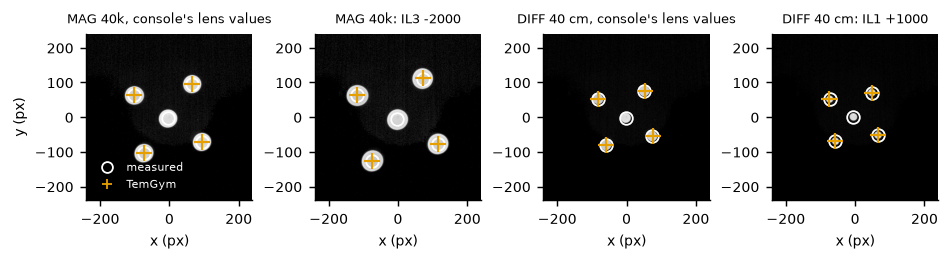

In [13]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130})
BLUE, ORANGE, GREEN, RED = "#0072B2", "#E69F00", "#009E73", "#D55E00"

stage1_zip = zipfile.ZipFile(RECORDINGS / "imaging-system-fitting-40k-40cm.zip")
folder_in_zip = table_name.rsplit("/", 1)[0]


def load_frame(archive, folder, row):
    frame = np.load(io.BytesIO(archive.read(f"{folder}/{row['frame']}"))).astype(float)
    return frame - np.median(frame)                           # the camera's dark level


not_deflected = {(r["mode"], r["setting"]): r for r in table if r["number"] and r["role"] == "not deflected"}
row_of = {(m["mode"], m["setting"], m["direction"]): i for i, m in enumerate(fitted)}
shown = ["MAG 40k row", "MAG 40k: IL3 -2000", "DIFF 40 cm row", "DIFF 40 cm: IL1 +1000"]

fig, axes_row = plt.subplots(1, 4, figsize=(7.2, 2.2), constrained_layout=True)
for ax, setting in zip(axes_row, shown):
    mode = setting.split(":")[0].replace(" row", "")
    mode = "MAG 40k" if setting.startswith("MAG") else "DIFF 40 cm"
    still = not_deflected[(mode, setting)]
    number = still["number"]
    frames = [still] + [r for r in table if r["number"] == number and r["mode"] == mode and r["role"].startswith("deflected")]
    total = sum(np.clip(load_frame(stage1_zip, folder_in_zip, r), 0, None) for r in frames)
    n = total.shape[0]
    ax.imshow(np.sqrt(total), origin="lower", cmap="gray", extent=(-n / 2, n / 2, -n / 2, n / 2))
    base = centre(still)
    ax.plot(base.real, base.imag, "o", mfc="none", mec="white", ms=7, mew=1)
    for direction in "xy":
        for role, sign in [("deflected +", +1), ("deflected -", -1)]:
            r = next(r for r in frames if r.get("role") == role and r["direction"] == direction)
            c = centre(r)
            guess = base + sign * predicted[row_of[(mode, setting, direction)]]
            ax.plot(c.real, c.imag, "o", mfc="none", mec="white", ms=7, mew=1)
            ax.plot(guess.real, guess.imag, "+", color=ORANGE, ms=9, mew=1.2)
    ax.set_title(setting.replace(" row", ", console's lens values"), fontsize=7)
    ax.set_xlabel("x (px)")
axes_row[0].set_ylabel("y (px)")
axes_row[0].plot([], [], "o", mfc="none", mec="white", label="measured")
axes_row[0].plot([], [], "+", color=ORANGE, label="TemGym")
axes_row[0].legend(loc="lower left", fontsize=6, frameon=False, labelcolor="white")
plt.show()

**Figure 2, how far off TemGym is.** Left: each fitted displacement (TemGym minus measured, in pixels) against the size of the displacement;
the grey band is the repeat scatter of section 3. Right: the settings kept back, by the DAC step of the lens that
was changed. IL1 in DIFF is the one that grows.

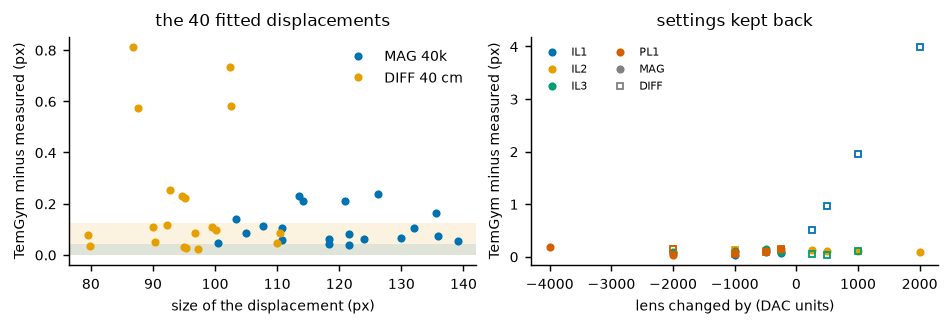

In [14]:
fig, (left, right) = plt.subplots(1, 2, figsize=(7.2, 2.4), constrained_layout=True)
for mode, colour in [("MAG 40k", BLUE), ("DIFF 40 cm", ORANGE)]:
    chosen = np.array([m["mode"] == mode for m in fitted])
    left.plot(np.abs(data["displacement"][chosen]), np.abs(predicted - data["displacement"])[chosen], "o", color=colour, ms=3.5, label=mode)
    left.axhspan(0, scatter[mode], color=colour, alpha=0.12, lw=0)
left.set(xlabel="size of the displacement (px)", ylabel="TemGym minus measured (px)", title="the 40 fitted displacements")
left.legend(frameon=False)
lens_colours = dict(zip(LENSES, [BLUE, ORANGE, GREEN, RED]))
for lens_name in LENSES:
    for mode, marker in [("MAG 40k", "o"), ("DIFF 40 cm", "s")]:
        points = [(step, miss) for m, l, step, miss in held_out if l == lens_name and m == mode]
        if points:
            right.plot(*zip(*points), marker, color=lens_colours[lens_name], ms=3.5, mfc=lens_colours[lens_name] if marker == "o" else "none")
for lens_name in LENSES:
    right.plot([], [], "o", color=lens_colours[lens_name], ms=3.5, label=lens_name)
right.plot([], [], "o", color="grey", ms=3.5, label="MAG")
right.plot([], [], "s", color="grey", mfc="none", ms=3.5, label="DIFF")
right.set(xlabel="lens changed by (DAC units)", ylabel="TemGym minus measured (px)", title="settings kept back")
right.legend(frameon=False, ncol=2, fontsize=6)
plt.show()

**Figure 3, the second experiment.** Left: the beam at four magnifications of `beam_per_magnification.py`, each with the
beam centred and 20 % of the frame. Right: how far TemGym's beam shift response (per CLA1 unit) is off, in size and in angle, at every
magnification, once the common factor at 40k is taken out. The IL1 to PL1 values are the assumed lens table (section 9).

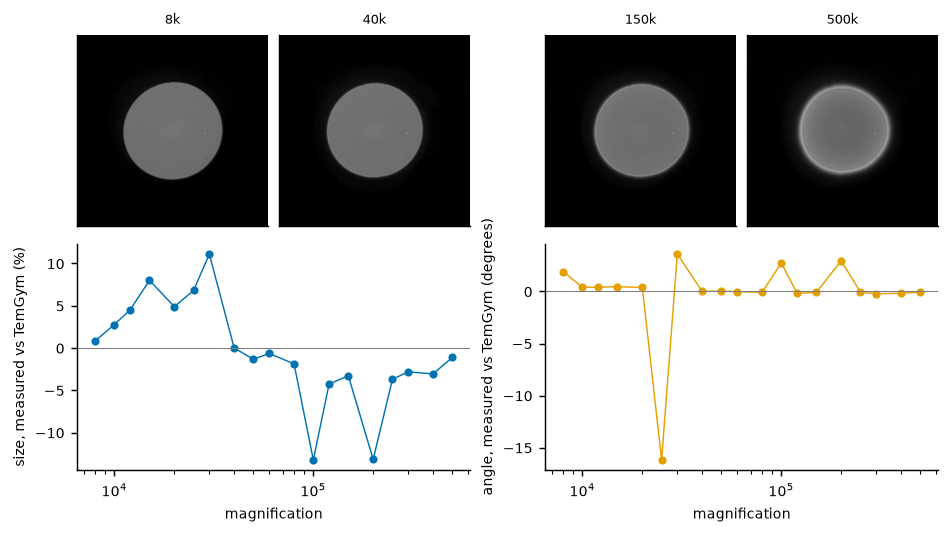

In [15]:
mag_zip = zipfile.ZipFile(RECORDINGS / "beam_per_magnification.zip")
mag_folder = name.rsplit("/", 1)[0]
fig = plt.figure(figsize=(7.2, 4.0), constrained_layout=True)
grid = fig.add_gridspec(2, 4, height_ratios=[1, 1.1])
for k, mag in enumerate([8000, 40000, 150000, 500000]):
    ax = fig.add_subplot(grid[0, k])
    row = next(r for r in by_magnification if int(r["magnification"]) == mag)
    frame = np.load(io.BytesIO(mag_zip.read(f"{mag_folder}/{row['frame']}"))).astype(float)
    frame -= np.median(frame)
    n = frame.shape[0]
    ax.imshow(np.sqrt(np.clip(frame, 0, None)), origin="lower", cmap="gray", extent=(-n / 2, n / 2, -n / 2, n / 2))
    ax.set_title(f"{mag // 1000}k", fontsize=7)
    ax.set_xticks([]); ax.set_yticks([])
ratio = measured / (model * factor)
size_ax = fig.add_subplot(grid[1, :2]); angle_ax = fig.add_subplot(grid[1, 2:])
size_ax.semilogx(magnifications, 100 * (np.abs(ratio) - 1), "o-", color=BLUE, ms=3.5, lw=0.8)
angle_ax.semilogx(magnifications, np.degrees(np.angle(ratio)), "o-", color=ORANGE, ms=3.5, lw=0.8)
for ax_, label in [(size_ax, "size, measured vs TemGym (%)"), (angle_ax, "angle, measured vs TemGym (degrees)")]:
    ax_.axhline(0, color="grey", lw=0.6)
    ax_.set(xlabel="magnification", ylabel=label)
plt.show()

## 11. The fitted lenses, and the model saved

In [16]:
lenses = numbers["lenses"]
ampere_turns_40k = np.asarray(lenses["ampere_turns_per_unit"]) * np.array(row_40k["lenses"])
example = column(lenses, jnp.array(row_40k["lenses"]))
print("at the 40k row:")
for name, lens in zip(LENSES, example[1:5]):
    print(f"   {name}: {float(lens.excitation):+7.0f} ampere-turns, focal length {float(lens.focal_length(VOLTAGE)) * 1e3:7.2f} mm, "
          f"thickness {float(lens.thickness) * 1e3:6.2f} mm, turns the image {np.degrees(float(lens.rotation_angle(VOLTAGE))):+7.1f} degrees")

folder = RESULTS / "fit_2026-11-10"
folder.mkdir(exist_ok=True)
(folder / "projection_model.json").write_text(json.dumps(dict(
    about="TemGym ElectromagneticLens column (objective, IL1, IL2, IL3, PL1) fitted to the NEOARM stage-1 recording of 2026-11-10 "
          "at 200 kV by fit_projection_response.ipynb. Held, not measured: the PL1-to-camera gap and the shift per CLA1 unit. "
          "The gaps are not the real lens positions.",
    numbers=numbers, repeat_scatter_px=scatter, chi2=best["chi2"], dof=best["dof"], pixel_m=PIXEL, voltage_v=VOLTAGE,
), indent=1, default=lambda value: np.asarray(value).tolist()))
print("saved", folder / "projection_model.json")

at the 40k row:
   IL1:   -3338 ampere-turns, focal length   12.01 mm, thickness   2.23 mm, turns the image   -72.9 degrees
   IL2:   -2002 ampere-turns, focal length   28.13 mm, thickness   2.60 mm, turns the image   -43.7 degrees
   IL3:   -2894 ampere-turns, focal length   96.37 mm, thickness  40.76 mm, turns the image   -63.2 degrees
   PL1:   +5184 ampere-turns, focal length    0.95 mm, thickness   1.05 mm, turns the image  +113.2 degrees
saved results/fit_2026-11-10/projection_model.json


## 12. The virtual NEOARM from this fit

The fitted lenses become the hidden optics of the simulated microscope (`examples/virtual_neoarm/virtual_neoarm.json`),
so scripts rehearsed on it see the projection lenses the real NEOARM has. What goes in, and where it comes from:

* **Fitted here:** IL1, IL2, IL3, PL1 and the objective (TemGym `ElectromagneticLens`es at the fitted places), CLA1
  and CLA2 (their axes, as a 4 x 4 matrix from DAC units to shift and tilt at the specimen), the camera's rotation.
* **Fitted to the recordings with these lenses:** the beam's size at the specimen as CL3 changes (from the beam sizes
  of the magnification recording), and its spread of angles (from the beam's size in DIFF at 40 cm).
* **As recorded on the day:** the MAG lens table (8k to 600k), the DIFF row at 40 cm (the only camera length
  recorded), the objective's and the condenser lenses' DAC values, the camera (479 x 479 px, not mirrored).
* **Held, as in the fit:** the PL1-to-camera gap and the shift per CLA1 unit. So lengths at the specimen (beam size,
  shift) are in the fit's units, not real nanometres; everything on the camera is in real pixels.
* **Left out:** lens offsets, PLA, the objective's aberrations (the old file had made-up ones), and anything the
  condenser does other than CL3 setting the beam's size.

In [17]:
modes_name = next(n for n in stage1_zip.namelist() if n.endswith("modes.json"))
console = json.loads(stage1_zip.read(modes_name))
FREE_LENS_NUMBER = {"IL1": 10, "IL2": 11, "IL3": 12, "PL1": 14}       # PyJEM free-lens numbers
diff_row = {n: console["DIFF 40 cm"]["lenses"][n] for n in LENSES}
lens_numbers = {k: np.asarray(v) for k, v in numbers["lenses"].items()}
places = np.cumsum(np.exp(lens_numbers["log_gaps"]))             # objective, IL1, IL2, IL3, PL1, camera (m from the specimen)


def axes_of(deflector):
    """A deflector's x and y axes at the specimen, as complex numbers (m or rad per DAC unit)."""
    x_axis = np.exp(float(numbers[deflector]["log_size"]) + 1j * float(numbers[deflector].get("x_angle", 0.0)))
    return x_axis, x_axis * complex(*np.asarray(numbers[deflector]["y_axis"]))


(shift_x, shift_y), (tilt_x, tilt_y) = axes_of("CLA1"), axes_of("CLA2")
kick_per_dac = [[shift_x.real, shift_y.real, 0, 0], [shift_x.imag, shift_y.imag, 0, 0],
                [0, 0, tilt_x.real, tilt_y.real], [0, 0, tilt_x.imag, tilt_y.imag]]

The beam on the camera has an rms size from two parts: its size at the specimen times |A|, and its spread of angles
times |B| (rms on the camera squared = (|A| size)^2 + (|B| spread)^2). The stage-1 frames at the console's lenses, in
MAG 40k and in DIFF 40 cm, were taken at the same CL3, so those two give the size and the spread there.

The magnification recording made the beam the same size on the camera (rms about 60 px) at every row; with the
spread known, each row gives the size at the specimen for its CL3. A law sqrt(smallest^2 + (rate x (CL3 - CL3 at
the smallest))^2) is fitted to those. The four rows whose lens table looks wrong (section 9) are left out.

In [18]:
def a_and_b_at(rows):
    a, b = a_and_b(lenses, np.asarray(rows, float))
    return np.abs(np.asarray(a)), np.abs(np.asarray(b))


still = {mode: next(r for r in table if r["mode"] == mode and r["setting"] == f"{mode} row") for mode in ["MAG 40k", "DIFF 40 cm"]}
(a_mag, a_diff), (b_mag, b_diff) = a_and_b_at([row_40k["lenses"], [diff_row[n] for n in LENSES]])
rms_on_camera = np.array([float(still[mode]["beam_rms_px"]) for mode in still]) * PIXEL
size_squared, spread_squared = np.linalg.solve([[a_mag ** 2, b_mag ** 2], [a_diff ** 2, b_diff ** 2]], rms_on_camera ** 2)
size_40k, angle_spread = np.sqrt(size_squared), np.sqrt(spread_squared)
print(f"at CL3 {still['MAG 40k']['CL3']}: beam size {size_40k:.3e} m rms at the specimen (in the fit's units), "
      f"spread of angles {angle_spread:.3e} rad rms")

suspect_rows = {25000, 30000, 100000, 200000}
chosen = np.array([m not in suspect_rows for m in magnifications])
a_rows, b_rows = a_and_b_at(table_arrays["lenses"])
from_angles = (b_rows * angle_spread) ** 2
measured_rms = np.array([float(row["beam_rms_px"]) for row in by_magnification]) * PIXEL
cl3 = np.r_[[float(row["CL3"]) for row in by_magnification], float(still["MAG 40k"]["CL3"])][np.r_[chosen, True]]
size_at_specimen = np.r_[np.sqrt(np.clip(measured_rms ** 2 - from_angles, 0, None)) / a_rows, size_40k][np.r_[chosen, True]]


def size_law(p, cl3):
    return np.hypot(np.exp(p[0]), np.exp(p[1]) * (cl3 - p[2]))


law = least_squares(lambda p: size_law(p, cl3) / size_at_specimen - 1,
                    [np.log(size_at_specimen.min() / 2), np.log(np.ptp(size_at_specimen) / np.ptp(cl3)), cl3.min() - 300]).x
smallest = f"{np.exp(law[0]):.2e} m" if np.exp(law[0]) > 1e-13 else "about 0"
print(f"beam size law: smallest ({smallest}) at CL3 {law[2]:.0f}, growing {np.exp(law[1]):.3e} m per CL3 unit; "
      f"misses the sizes found by {100 * np.sqrt(np.mean((size_law(law, cl3) / size_at_specimen - 1) ** 2)):.1f} % rms")

at CL3 33866: beam size 1.102e-09 m rms at the specimen (in the fit's units), spread of angles 8.489e-04 rad rms
beam size law: smallest (about 0) at CL3 33402, growing 3.071e-12 m per CL3 unit; misses the sizes found by 8.4 % rms


In [19]:
mag_rows = {str(m): {n: row[n] for n in LENSES} for m, row in sorted(lens_table.items()) if 8000 <= m <= 600000}
virtual = dict(
    description="The virtual NEOARM at 200 kV, written by fit_projection_response.ipynb from the recording of 2026-11-10. "
                "Fitted: the objective and IL1-PL1 (TemGym ElectromagneticLens), CLA1/CLA2 axes (kick_per_dac), the camera "
                "rotation; then, with those lenses, the CL3 beam-size law and the spread of angles. As recorded: the MAG "
                "lens table, the DIFF 40 cm row, the objective DAC values, the camera. Held (not measured): the PL1-to-camera "
                "gap and the CLA1 shift per unit, so specimen-plane lengths are in the fit's units. Left out: lens offsets, "
                "PLA, aberrations.",
    reference_voltage_v=VOLTAGE,
    lenses=dict(objective=dict(z_m=places[0], ampere_turns=1.0, Gc=float(np.exp(lens_numbers["log_objective_Gc"]))),
                **{n: dict(z_m=places[i + 1], ampere_turns_per_dac=float(lens_numbers["ampere_turns_per_unit"][i]),
                           Gc=float(np.exp(lens_numbers["log_Gc"][i])), Tc=float(np.exp(lens_numbers["log_Tc"][i])))
                   for i, n in enumerate(LENSES)}),
    camera_z_m=places[5], camera_rotation_rad=float(numbers["camera_rotation"]),
    camera=dict(name="screenCamera", sensor_shape=[1916, 1916], sensor_pixel_m=PIXEL / 4, binnings=[1, 2, 4],
                psf_sigma_sensor_pixels=4.0, mirrored=False),
    deflectors=dict(kick_per_dac=kick_per_dac),
    beam=dict(rms_size_m=float(size_40k), rms_angle_rad=float(angle_spread), current_a=1.602e-9),
    beam_size=dict(CL3_smallest_dac=float(law[2]), smallest_rms_m=float(np.exp(law[0])), rms_m_per_dac=float(np.exp(law[1]))),
    objective_dac={n: console["MAG 40k"]["lenses"][n] for n in ("OLc", "OLf")},
    condenser_dac={n: console["MAG 40k"]["lenses"][n] for n in ("CL1", "CL2", "CL3", "CM")},
    lens_table=dict(MAG=mag_rows, DIFF={"0.4": diff_row}),
)
virtual_file = Path("../virtual_neoarm/virtual_neoarm.json")
virtual_file.write_text(json.dumps(virtual, indent=1, default=lambda value: np.asarray(value).tolist()))
print("written", virtual_file)

written ../virtual_neoarm/virtual_neoarm.json


## 13. The virtual NEOARM against the real one

The simulated microscope is driven through its PyJEM calls exactly as `record_projection_response.py` drove the real
one: at each of the 20 recorded lens settings, CLA1 (MAG) or CLA2 (DIFF) + and - along x and y, with the recorded
deflections, and the beam found in each frame with the same `find_beam`. The displacements should agree with the real
ones as well as the fit did (section 7), and the beam's size at the console's lenses should match.

In [20]:
import sys
sys.path.insert(0, "at_the_microscope")
from neoarm import find_beam                                                      # noqa: E402
from temgym_core.pyjem_simulator import SimulatedMicroscope                       # noqa: E402

simulated = SimulatedMicroscope.from_file(virtual_file, ht_v=VOLTAGE, magnification=40000, diffraction_camera_length_m=0.4,
                                          ray_sample_power=17, detector_samples_per_pixel=2)
TEM3, detector = simulated.pyjem()
sim_camera = detector.Detector(detector.get_attached_detector()[0])
sim_lens, sim_deflectors, sim_eos = TEM3.Lens3(), TEM3.Def3(), TEM3.EOS3()
shape = (sim_camera.get_detectorsetting()["ImagingArea"]["Height"], sim_camera.get_detectorsetting()["ImagingArea"]["Width"])


def simulated_centre():
    beam = find_beam(frame=np.frombuffer(sim_camera.snapshot_rawdata(), "<i4").reshape(shape))
    return beam.centre, beam.rms


sim_displacement, sim_rms = [], {}
for m in fitted:
    mode_number = 4 if m["deflector"] == "CLA2" else 0
    if sim_eos.GetFunctionMode()[0] != mode_number:
        sim_eos.SelectFunctionMode(mode_number)
    for name, value in zip(LENSES, m["lenses"]):
        sim_lens.SetFLCAbs(FREE_LENS_NUMBER[name], int(value))
        sim_lens.SetFLCSw(FREE_LENS_NUMBER[name], 1)
    setter = getattr(sim_deflectors, "Set" + m["deflector"])
    if m["setting"].endswith("row"):
        sim_rms[m["mode"]] = simulated_centre()[1]
    centres = []
    for sign in (+1, -1):
        d = sign * m["deflection"]
        setter(32768 + int(d.real), 32768 + int(d.imag))
        centres.append(simulated_centre()[0])
    setter(32768, 32768)
    sim_displacement.append((centres[0] - centres[1]) / 2)
sim_displacement = np.array(sim_displacement)
off = np.abs(sim_displacement - data["displacement"])
for mode, chosen in [("MAG 40k (CLA1)", ~data["is_tilt"]), ("DIFF 40 cm (CLA2)", data["is_tilt"])]:
    print(f"{mode}: virtual NEOARM vs real, {np.sqrt(np.mean(off[chosen] ** 2)):.2f} px rms, {off[chosen].max():.2f} px at worst")
for mode in ["MAG 40k", "DIFF 40 cm"]:
    real_rms = float(still[mode]["beam_rms_px"])
    print(f"{mode}: beam rms at the console's lenses, virtual {sim_rms[mode]:.1f} px, real {real_rms:.1f} px")

MAG 40k (CLA1): virtual NEOARM vs real, 0.13 px rms, 0.24 px at worst
DIFF 40 cm (CLA2): virtual NEOARM vs real, 0.32 px rms, 0.81 px at worst
MAG 40k: beam rms at the console's lenses, virtual 16.7 px, real 13.3 px
DIFF 40 cm: beam rms at the console's lenses, virtual 7.6 px, real 7.3 px
